# - Master Kode Tugas NLP Trio Bertiga -

**Proyek:** Prediksi Peristiwa Geopolitik Global | Dampak terhadap Nilai Tukar USD/IDR.
**Hipotesis:** berita geopolitik global berpengaruh signifikan terhadap fluktuasi kurs USD/IDR.

Notebook ini adalah **master kode** gabungan seluruh kode yang dipakai pada **Tugas 1–3**. Disusun mengikuti **alur proses** (bisa dijalankan dari atas ke bawah), dengan **tag role** di tiap sesi.

### Tim
| Anggota | Role utama |
|---|---|
| **Mikail Achmad** (24/542370/PA/23026) | Akuisisi data kurs & temporal alignment, formulasi target, split, naive baseline, fusion & analisis error |
| **Widad Muhammad Rafi** (24/545635/PA/23190) | Scraping berita, align/merge, transformer embedding (FinBERT), studi ablasi |
| **Pratama Nanindra Aji** (24/533677/PA/22604) | Cleaning & filtering teks, fitur NLP dasar, static embedding, LDA, XGBoost |

### Cara pakai
1. Jalankan **Sesi 0 (Setup)** lebih dulu untuk mengatur path, import, dan flag `RUN_HEAVY`.
2. Tiap sesi diberi tag `[Nama]`. Isi/ubah **hanya sesi role**.
3. Sesi berat (scraping, FinBERT, unduh GloVe, LDA) default **membaca cache**, set `RUN_HEAVY = True` di Sesi 0 untuk menghitung ulang.
4. Sesi tim lain yang belum diisi akan memunculkan `NotImplementedError` by design (ada **kontrak input/output** di tiap placeholder sebagai panduan menambal).

## Peta Kontribusi (proses → role → status)

| # | Proses | Role | Status |
|---|---|---|---|
| 1.1 | Scraping Berita CNBC | Rafi | ✅ terisi |
| 1.2 | Akuisisi + Cleaning Kurs JISDOR | **Mikail** | ✅ terisi |
| 1.3 | Cleaning + Filtering + Preprocessing Teks | Aji | ✅ terisi |
| 1.4 | Temporal Alignment berita↔hari bursa | **Mikail** | ✅ terisi |
| 1.5 | Visualisasi Tren Kurs | **Mikail** | ✅ terisi |
| 2.1 | Formulasi Target (3-class + regresi) | **Mikail** | ✅ terisi |
| 2.2 | Split Kronologis Train/Val/Test | **Mikail** | ✅ terisi |
| 2.3 | Naive Baseline (Persistence/Majority) | **Mikail** | ✅ terisi |
| 2.4 | Fitur NLP Dasar (lexicon + TF-IDF/SVD) | Aji/Rafi | ✅ terisi |
| 2.5 | XGBoost TS-only / NLP-only / Gabungan | Aji | ✅ terisi |
| 3.1 | Static Embeddings (W2V/FastText/GloVe) | Aji | ✅ terisi |
| 3.2 | Topic Modeling LDA + t-SNE | Aji | ⬜ placeholder |
| 3.3 | Transformer Embedding FinBERT (Model C) | Rafi | ✅ terisi |
| 3.4 | Fusion Early + Late | **Mikail** | ✅ terisi |
| 3.5 | Studi Ablasi A/B/C + Model A+ (tuning) + Matriks | **Mikail** | ✅ terisi |
| 3.6 | Analisis Korelasi & Error | **Mikail** | ✅ terisi |

## 0. Setup & Konfigurasi  &nbsp;·&nbsp; `[Bersama]`

In [1]:
# Path & environment
import os, sys, json
from pathlib import Path

# REPO_ROOT = folder notebook ini (main.ipynb ada di root repo).
REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "src").exists() and (REPO_ROOT.parent / "src").exists():
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT))

# Toggle langkah berat
# False = baca cache (cepat, tanpa GPU/unduhan). True = hitung ulang dari mentah.
RUN_HEAVY = False

# Folder standar
PATHS = {
    "processed": REPO_ROOT / "data" / "processed",
    "split":     REPO_ROOT / "data" / "split",          # <- split kanonik
    "features":  REPO_ROOT / "data" / "feature_extracted",
    "results":   REPO_ROOT / "results",
}

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

print("REPO_ROOT :", REPO_ROOT)
print("RUN_HEAVY :", RUN_HEAVY)

REPO_ROOT : d:\Kuliah\Tugas dan Projek\Pemrosesan Bahasa Alami\repo\nlp-trio-bertiga
RUN_HEAVY : False


In [2]:
# Helper bersama
def load_json(name: str) -> dict:
    """Baca file JSON dari folder results/."""
    with open(PATHS["results"] / name, "r", encoding="utf-8") as f:
        return json.load(f)

def show_results(name: str, splits=("val", "test")):
    """Ringkas metrik klasifikasi+regresi dari file *_results.json."""
    d = load_json(name)
    rows = []
    for s in splits:
        clf = d.get("classification", {}).get(s, {})
        reg = d.get("regression", {}).get(s, {})
        rows.append({
            "split": s,
            "accuracy": clf.get("accuracy"),
            "macro_f1": clf.get("macro_f1"),
            "rmse": reg.get("rmse"),
            "skill_vs_naive": reg.get("skill_vs_naive"),
            "directional_hit": reg.get("directional_hit"),
        })
    return pd.DataFrame(rows)

def show_png(name: str, width=560):
    """Tampilkan gambar hasil dari results/ (jika ada)."""
    from IPython.display import Image, display
    p = PATHS["results"] / name
    display(Image(filename=str(p), width=width)) if p.exists() else print("(belum ada)", p.name)

---
# TUGAS 1 | Akuisisi Data & Preprocessing Strategis

### 1.1 Scraping Berita CNBC &nbsp;·&nbsp; `[Rafi]`

Google News RSS menemukan artikel berdasarkan kata kunci dan jendela 7 hari. URL hasil discovery diubah ke URL CNBC dan dideduplikasi, lalu isi, judul, tanggal, dan penulis diambil dari halaman artikel. Kolom `discovery_title` diteruskan untuk filtering seksi 1.3.

Default memuat `data/raw/news/cnbc_articles_final.csv`. Set `RUN_HEAVY=True` untuk mengambil ulang berita dalam periode penelitian.

In [3]:
# Google News RSS → URL CNBC → metadata JSON-LD dan isi artikel.
NEWS_RAW = REPO_ROOT / "data" / "raw" / "news" / "cnbc_articles_final.csv"
NEWS_START, NEWS_END = "2021-09-01", "2026-09-01"  # akhir eksklusif

if RUN_HEAVY:
    from datetime import date, timedelta
    from time import sleep
    from urllib.parse import urlsplit
    from xml.etree import ElementTree

    import requests
    from bs4 import BeautifulSoup
    from googlenewsdecoder import gnewsdecoder
    from requests.adapters import HTTPAdapter
    from tqdm.auto import tqdm
    from urllib3.util.retry import Retry

    news_queries = [
        "geopolitics", "geopolitical", "war", "conflict", "Ukraine", "Russia",
        "China", "Israel", "Gaza", "Iran", "Middle East", "United States",
        "trade war", "tariffs", "dollar", "USD", "currency", "exchange rate",
        "Federal Reserve", "interest rates",
    ]

    def cnbc_url(url):
        parsed = urlsplit(url or "")
        host = parsed.hostname or ""
        if parsed.scheme not in {"http", "https"} or not (
            host == "cnbc.com" or host.endswith(".cnbc.com")
        ):
            return None
        host = "www.cnbc.com" if host == "cnbc.com" else host
        return f"https://{host}{parsed.path.rstrip('/')}"

    def discover_cnbc(session, start, end):
        candidates = {}
        starts = pd.date_range(start, end - timedelta(days=1), freq="7D").date
        for first in tqdm(starts, desc="Penelusuran RSS CNBC"):
            last = min(first + timedelta(days=7), end)
            for keyword in news_queries:
                query = f"site:cnbc.com {keyword}"
                response = session.get(
                    "https://news.google.com/rss/search",
                    params={"q": f"{query} after:{first} before:{last}",
                            "hl": "en-US", "gl": "US", "ceid": "US:en"},
                    timeout=30,
                )
                response.raise_for_status()
                for item in ElementTree.fromstring(response.content).findall("./channel/item"):
                    link = item.findtext("link", "").strip()
                    source = item.find("source")
                    if link and (cnbc_url(link) or
                                 (source is not None and cnbc_url(source.get("url")))):
                        candidates.setdefault(link, {
                            "rss_link": link,
                            "discovery_title": item.findtext("title", "").strip(),
                            "discovery_published": item.findtext("pubDate", ""),
                            "discovery_query": query,
                        })
                sleep(0.5)
        return candidates.values()

    def jsonld_items(data):
        if isinstance(data, list):
            for item in data:
                yield from jsonld_items(item)
        elif isinstance(data, dict):
            yield data
            yield from jsonld_items(data.get("@graph"))

    def parse_cnbc(html):
        soup = BeautifulSoup(html, "html.parser")
        metadata = {}
        for script in soup.select('script[type="application/ld+json"]'):
            try:
                data = json.loads(script.string or "")
            except json.JSONDecodeError:
                continue
            metadata = next((item for item in jsonld_items(data)
                             if item.get("headline") or item.get("articleBody")), {})
            if metadata:
                break

        heading = soup.find("h1")
        timestamp = soup.select_one("time[datetime]")
        title = metadata.get("headline") or (heading.get_text(" ", strip=True) if heading else "")
        published = metadata.get("datePublished") or (timestamp["datetime"] if timestamp else "")
        authors = metadata.get("author") or []
        if not isinstance(authors, list):
            authors = [authors]
        names = [author.get("name") if isinstance(author, dict) else author for author in authors]
        author = ", ".join(name for name in names if isinstance(name, str) and name.strip())
        if not author:
            author = ", ".join(a.get_text(" ", strip=True) for a in soup.select("a.Author-authorName"))

        body = ""
        for selector in (".ArticleBody-articleBody p", ".article-content p",
                         "[class*='ArticleBody'] p", "article p"):
            paragraphs = [p.get_text(" ", strip=True) for p in soup.select(selector)]
            body = "\n".join(dict.fromkeys(p for p in paragraphs if p))
            if len(body) >= 300:
                break
        if len(body) < 300:
            body = metadata.get("articleBody") or body
        return {"title": title, "published_at": published, "author": author, "body": body}

    def scrape_cnbc(session, candidates, start, end):
        articles = {}
        attempted_urls = set()
        for candidate in tqdm(candidates, desc="Scraping CNBC"):
            link = candidate["rss_link"]
            url = cnbc_url(link)
            if url is None and urlsplit(link).hostname == "news.google.com":
                decoded = gnewsdecoder(link, interval=1)
                url = cnbc_url(decoded.get("decoded_url")) if decoded.get("success") else None
            if url is None or url in attempted_urls or url in articles:
                continue
            attempted_urls.add(url)

            try:
                response = session.get(url, timeout=30)
                response.raise_for_status()
            except requests.RequestException:
                continue
            finally:
                sleep(1)

            final_url = cnbc_url(response.url)
            if final_url is None or final_url in articles:
                continue
            article = parse_cnbc(response.text)
            published = pd.to_datetime(article["published_at"], errors="coerce", utc=True)
            if (pd.isna(published) or not start <= published.date() < end or
                    not all(article.values()) or len(article["body"]) < 300):
                continue
            articles[final_url] = {
                "url": final_url, **article, "status": "success", "error": "",
                **candidate, "discovery_title": candidate["discovery_title"] or article["title"],
            }
        return pd.DataFrame(articles.values())

    start, end = date.fromisoformat(NEWS_START), date.fromisoformat(NEWS_END)
    with requests.Session() as session:
        session.headers.update({"User-Agent": "Mozilla/5.0", "Accept-Language": "en-US,en;q=0.9"})
        session.mount("https://", HTTPAdapter(max_retries=Retry(
            total=2, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504],
        )))
        candidates = discover_cnbc(session, start, end)
        news_raw = scrape_cnbc(session, candidates, start, end)
    if news_raw.empty:
        raise RuntimeError("RSS dan scraping tidak menghasilkan artikel CNBC yang lengkap.")
    NEWS_RAW.parent.mkdir(parents=True, exist_ok=True)
    temp_csv = NEWS_RAW.with_suffix(".tmp")
    news_raw.to_csv(temp_csv, index=False)
    temp_csv.replace(NEWS_RAW)
    print(f"Tersimpan di {NEWS_RAW.name}")
else:
    if not NEWS_RAW.exists():
        raise FileNotFoundError(f"Cache {NEWS_RAW} belum ada. Set RUN_HEAVY=True untuk scraping.")
    news_raw = pd.read_csv(NEWS_RAW)

print(f"Data mentah CNBC: {len(news_raw):,} baris")
news_raw.head()

### 1.2 Akuisisi + Cleaning Kurs JISDOR &nbsp;·&nbsp; `[Mikail]`

Sumber mutlak **Bank Indonesia (JISDOR)**, periode 2021-09 → 2026-08. Pipeline:
baca XLSX/CSV mentah → standarisasi kolom tanggal → validasi (duplikat, tanggal
rusak, kurs non-positif) → urut kronologis. Modul: `src/jisdor/preprocess_jisdor.py`.

In [4]:
from src.jisdor.preprocess_jisdor import load_jisdor_csv, preprocess_jisdor

JISDOR_CLEAN = PATHS["processed"] / "jisdor_clean.csv"

if RUN_HEAVY:
    # Jalankan ulang cleaning dari sumber mentah (sesuaikan path XLSX bila perlu).
    raw = load_jisdor_csv(PATHS["processed"].parent / "raw" / "Informasi_Kurs_Jisdor.xlsx")
    jisdor = preprocess_jisdor(raw)
    jisdor.to_csv(JISDOR_CLEAN, index=False, date_format="%Y-%m-%d")
else:
    jisdor = pd.read_csv(JISDOR_CLEAN, parse_dates=["tanggal"])

print(f"Kurs JISDOR bersih: {len(jisdor)} hari | {jisdor['tanggal'].min().date()} → {jisdor['tanggal'].max().date()}")
jisdor.head()

Kurs JISDOR bersih: 1202 hari | 2021-09-01 → 2026-09-01


,tanggal,kurs_jisdor
0,2021-09-01,14284
1,2021-09-02,14281
2,2021-09-03,14261
3,2021-09-06,14239
4,2021-09-07,14195


### 1.3 Cleaning + Filtering + Preprocessing Teks &nbsp;·&nbsp; `[Aji]`

Proses data preparation melalui tahap cleaning, filtering, dan preprocessing.
1. **Cleaning:** teks (hapus tag, entitas, dan karakter yang tidak diperlukan).
2. **Filtering:** validasi kolom wajib dan pilih berita yang relevan berdasarkan kata kunci geopolitik.
3. **Preprocessing:** hasilkan `text_clean_light` untuk pemrosesan umum dan `text_clean_classical` beserta token untuk analisis klasik.

Modul: 
- `src/cleaning/text_cleaning.py`
- `src/filtering/text_filtering.py`
- `src/preprocessing/text_preprocessing.py`

In [16]:
# TODO [Aji] | Cleaning HTML -> filtering relevansi geopolitik -> preprocessing (light & classical)
# INPUT  : data/raw/news/*.csv (hasil scraping 1.1)
# PROSES : cleaning.clean_text -> filter_news (field wajib + keyword geopolitik)
#          -> preprocess_documents (text_clean_light & text_clean_classical/tokens)
# OUTPUT : data/processed/news_preprocessed.csv
# Acuan  : src/main.ipynb, src/filtering/text_filtering.py,
#          src/preprocessing/text_preprocessing.py, src/cleaning/Cleaning_article.ipynb
# Tempel kodemu di bawah ini. Pakai REPO_ROOT, PATHS, RUN_HEAVY,
# dan helper load_json()/show_results() dari sesi  0 agar konsisten.
# raise NotImplementedError("Sesi Aji belum diisi.")

output_path = PATHS["processed"] / "news_preprocessed.csv"

if output_path.exists() and not RUN_HEAVY:
    print(f"Sudah ada ({output_path.stat().st_size / 1e6:.0f} MB), lewati re-run "
          f"(set RUN_HEAVY=True di Seksi 0 untuk memaksa hitung ulang).")
    news = pd.read_csv(output_path)
else:
    from src.cleaning.text_cleaning import clean_text
    from src.filtering.text_filtering import filter_news
    from src.preprocessing.text_preprocessing import preprocess_documents

    raw_dir = REPO_ROOT / "data" / "raw" / "news"
    PATHS["processed"].mkdir(parents=True, exist_ok=True)

    raw_files = sorted(raw_dir.glob("*.csv"))
    if not raw_files:
        raise FileNotFoundError(f"Tidak ditemukan CSV berita di {raw_dir}")

    news = pd.concat(
        [pd.read_csv(path) for path in raw_files],
        ignore_index=True
    )

    required_columns = {"url", "title", "published_at", "body"}
    missing = required_columns - set(news.columns)
    if missing:
        raise ValueError(f"Kolom wajib tidak ditemukan: {sorted(missing)}")

    news = news.drop_duplicates(subset="url").copy()

    def clean_value(value):
        return clean_text(value) if pd.notna(value) else ""

    news["title"] = news["title"].map(clean_value)
    news["body"] = news["body"].map(clean_value)

    news = filter_news(news)
    if news is None or news.empty:
        raise ValueError("Tidak ada berita yang lolos filtering.")

    news = preprocess_documents(news)
    if news is None:
        raise ValueError("preprocess_documents harus mengembalikan DataFrame.")

    news.to_csv(output_path, index=False)
    print(f"Berhasil menyimpan {len(news)} berita ke {output_path}")

news.head()

Sudah ada (238 MB), lewati re-run (set RUN_HEAVY=True di Seksi 0 untuk memaksa hitung ulang).


,url,title,published_at,author,body,status,error,rss_link,discovery_title,discovery_published,discovery_query,geopolitical_matches,text_clean_light,text_clean_classical,tokens_classical,unigrams,bigrams,text_final
0,https://www.cnbc.com/2021/09/07/guinea-coup-ra...,Guinea coup rattles iron ore and bauxite marke...,2021-09-07T10:37:21+0000,Elliot Smith,A military junta claimed to have seized contro...,success,NaN,https://news.google.com/rss/articles/CBMiswFBV...,Guinea coup rattles iron ore and bauxite marke...,"Tue, 07 Sep 2021 07:00:00 GMT",site:cnbc.com geopolitics,"{'title': ['coup'], 'body': ['military', 'coup...",A military junta claimed to have seized contro...,military junta claimed seized control west afr...,"['military', 'junta', 'claimed', 'seized', 'co...","['military', 'junta', 'claimed', 'seized', 'co...","['military_junta', 'junta_claimed', 'claimed_s...",A military junta claimed to have seized contro...
1,https://www.cnbc.com/2021/09/08/carlyle-ceo-ke...,Carlyle CEO Kewsong Lee on what's driving the ...,2021-09-08T15:01:03+0000,Leslie Picker,Kewsong Lee is closing out one trip around the...,success,NaN,https://news.google.com/rss/articles/CBMizwFBV...,Carlyle CEO Kewsong Lee on what's driving the ...,"Wed, 08 Sep 2021 07:00:00 GMT",site:cnbc.com geopolitics,"{'title': [], 'body': ['summit'], 'discovery_t...",Kewsong Lee is closing out one trip around the...,kewsong lee closing one trip around sun sole c...,"['kewsong', 'lee', 'closing', 'one', 'trip', '...","['kewsong', 'lee', 'closing', 'one', 'trip', '...","['kewsong_lee', 'lee_closing', 'closing_one', ...",Kewsong Lee is closing out one trip around the...
2,https://www.cnbc.com/2021/09/02/chinas-regulat...,China's health-care sector could be Beijing's ...,2021-09-02T02:39:44+0000,Weizhen Tan,China's health-care sector will probably be th...,success,NaN,https://news.google.com/rss/articles/CBMiqwFBV...,China's health-care sector could be Beijing's ...,"Wed, 01 Sep 2021 07:00:00 GMT",site:cnbc.com geopolitics,"{'title': [], 'body': ['defense'], 'discovery_...",China's health-care sector will probably be th...,china health care sector will probably next fa...,"['china', 'health', 'care', 'sector', 'will', ...","['china', 'health', 'care', 'sector', 'will', ...","['china_health', 'health_care', 'care_sector',...",China's health-care sector will probably be th...
3,https://www.cnbc.com/2021/09/10/us-biden-china...,"Biden, Xi discuss avoiding confrontation in se...",2021-09-10T04:36:17+0000,Evelyn Cheng,BEIJING - Chinese President Xi Jinping and US ...,success,NaN,https://news.google.com/rss/articles/CBMijgFBV...,"Biden, Xi discuss avoiding confrontation in se...","Fri, 10 Sep 2021 07:00:00 GMT",site:cnbc.com geopolitics,"{'title': [], 'body': ['conflict', 'summit'], ...",BEIJING - Chinese President Xi Jinping and US ...,beijing chinese president jinping president jo...,"['beijing', 'chinese', 'president', 'jinping',...","['beijing', 'chinese', 'president', 'jinping',...","['beijing_chinese', 'chinese_president', 'pres...",BEIJING - Chinese President Xi Jinping and US ...
4,https://www.cnbc.com/2021/09/15/eu-von-der-ley...,EU chief calls for more military independence ...,2021-09-15T09:30:36+0000,Silvia Amaro,"LONDON - There is a new international order, w...",success,NaN,https://news.google.com/rss/articles/CBMinAFBV...,EU chief calls for more military independence ...,"Wed, 15 Sep 2021 07:00:00 GMT",site:cnbc.com geopolitics,"{'title': ['military'], 'body': ['troops', 'de...","LONDON - There is a new international order, w...",london new international order competition fie...,"['london', 'new', 'international', 'order', 'c...","['london', 'new', 'international', 'order', 'c...","['london_new', 'new_international', 'internati...","LONDON - There is a new international order, w..."


### 1.4 Temporal Alignment berita ↔ hari bursa &nbsp;·&nbsp; `[Mikail]`

Pasar beroperasi hari kerja; berita 24/7. Aturan: berita yang terbit **setelah jam
tutup pasar** didorong ke hari berikutnya, lalu **maju ke trading day** terdekat
(otomatis melompati akhir pekan & libur nasional via library `holidays`). Fungsi
inti di-*inline* di bawah agar mudah dijelaskan saat evaluasi.

In [17]:
from datetime import time
import holidays

MARKET_CLOSE_TIME = time(16, 0)                       # asumsi jam tutup pasar
ID_HOLIDAYS = holidays.Indonesia(years=range(2021, 2027))

def is_trading_day(date) -> bool:
    """True jika tanggal adalah hari bursa (bukan akhir pekan / libur nasional)."""
    d = pd.Timestamp(date).normalize()
    return d.weekday() < 5 and d.date() not in ID_HOLIDAYS

def get_effective_trading_date(news_datetime):
    """Petakan timestamp berita ke trading day kurs yang relevan."""
    ts = pd.Timestamp(news_datetime)
    d = ts.normalize()
    if is_trading_day(d) and ts.time() >= MARKET_CLOSE_TIME:   # setelah tutup -> besok
        d += pd.Timedelta(days=1)
    while not is_trading_day(d):                               # maju ke trading day
        d += pd.Timedelta(days=1)
    return d

# Demo aturan dengan contoh timestamp:
for ts in ["2023-01-16 09:00", "2023-01-16 17:30", "2022-12-25 08:00"]:
    print(f"  {ts:<20} → {get_effective_trading_date(ts).date()}")

# Integrasi ke data berita (jalankan setelah 1.3 menghasilkan news_preprocessed.csv):
#   news["trading_date"] = news["published_at"].apply(get_effective_trading_date)

  2023-01-16 09:00     → 2023-01-16
  2023-01-16 17:30     → 2023-01-17
  2022-12-25 08:00     → 2022-12-26


### 1.5 Visualisasi Tren Kurs &nbsp;·&nbsp; `[Mikail]`

Tren harian kurs JISDOR sepanjang periode penelitian. Modul lengkap (tahunan,
dengan anotasi peristiwa, output PNG/HTML plotly): `src/jisdor/visualize_jisdor.py`.

In [18]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(jisdor["tanggal"], jisdor["kurs_jisdor"], lw=1.1, color="#2563eb")
ax.set_title("Tren Kurs JISDOR USD/IDR (harian)")
ax.set_xlabel("Tanggal"); ax.set_ylabel("Kurs (IDR per USD)")
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Versi lengkap:
# from src.jisdor.visualize_jisdor import plot_trend_harian, plot_trend_tahunan
# plot_trend_harian()

C:\Users\Mikail Achmad\AppData\Local\Temp\ipykernel_19120\192943671.py:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


---
# TUGAS 2 | Baseline & Formulasi Target

### 2.1 Formulasi Target (3-class + regresi) &nbsp;·&nbsp; `[Mikail]`

Dua target dari sumber sama, keduanya untuk **besok** (shift −1):
- **Klasifikasi 3-class** `target`: NAIK / STABIL / TURUN, threshold ±0.1% pada
  `pct_change` (kelas STABIL mencegah ~30% hari ter-drop di dekat nol).
- **Regresi** `kurs_besok`: level kurs hari t+1.

Modul: `src/jisdor/target_formulation.py`. Fungsi inti di-*inline*:

In [19]:
THRESHOLD_PCT = 0.1

def label_direction(pct_change, threshold=THRESHOLD_PCT):
    """Label arah: NAIK / TURUN / STABIL (None bila NaN)."""
    if pd.isna(pct_change):
        return None
    if pct_change > threshold:
        return "NAIK"
    if pct_change < -threshold:
        return "TURUN"
    return "STABIL"

def build_target(df, threshold=THRESHOLD_PCT):
    """Tambah pct_change, target 3-class (besok), dan kurs_besok (regresi)."""
    df = df.copy()
    df["pct_change"] = df["kurs_jisdor"].pct_change() * 100
    df["target"] = df["pct_change"].apply(lambda x: label_direction(x, threshold)).shift(-1)
    df["kurs_besok"] = df["kurs_jisdor"].shift(-1)
    return df.dropna(subset=["target", "kurs_besok"]).reset_index(drop=True)

jisdor_target = build_target(jisdor.sort_values("tanggal").reset_index(drop=True))
print(f"{len(jisdor_target)} baris berlabel. Distribusi target:")
print(jisdor_target["target"].value_counts())
jisdor_target.head()

1201 baris berlabel. Distribusi target:
target
NAIK      477
STABIL    362
TURUN     362
Name: count, dtype: int64


,tanggal,kurs_jisdor,pct_change,target,kurs_besok
0,2021-09-01,14284,NaN,STABIL,14281.0
1,2021-09-02,14281,-0.021003,TURUN,14261.0
2,2021-09-03,14261,-0.140046,TURUN,14239.0
3,2021-09-06,14239,-0.154267,TURUN,14195.0
4,2021-09-07,14195,-0.309010,NAIK,14266.0


### 2.2 Split Kronologis Train/Val/Test &nbsp;·&nbsp; `[Mikail]`

Split **kronologis 80/10/10** (tanpa shuffle, menjaga urutan waktu & mencegah
kebocoran). Membawa kedua target sekaligus. Modul: `src/jisdor/split_dataset.py`.

In [20]:
from src.jisdor.split_dataset import chronological_split

train, val, test = chronological_split(jisdor_target)
for name, d in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:5s}: {len(d):4d} baris | {d['tanggal'].min().date()} → {d['tanggal'].max().date()}")
# Catatan: file resmi sudah tersimpan di data/split/{train,val,test}.csv

train:  959 baris | 2021-09-01 → 2025-08-26
val  :  119 baris | 2025-08-28 → 2026-02-19
test :  121 baris | 2026-02-23 → 2026-08-31


### 2.3 Naive Baseline &nbsp;·&nbsp; `[Mikail]`

Dua acuan minimal yang wajib dikalahkan model:
- **Persistence of Direction** | arah besok = arah hari ini.
- **Majority-Class** | selalu kelas mayoritas train.
- **Random Walk** (regresi) | kurs besok = kurs hari ini.

Modul lengkap (+ metrik & JSON): `src/models/naive_baseline.py`,
`src/models/naive_baseline_regression.py`. Fungsi inti di-*inline*:

In [21]:
from sklearn.metrics import accuracy_score, f1_score

def predict_persistence(targets: pd.Series):
    preds = targets.shift(1).values.copy()
    preds[0] = targets.mode().iloc[0]          # fallback baris pertama
    return preds

def predict_majority(targets_train: pd.Series, n: int):
    return np.full(n, targets_train.mode().iloc[0])

# Evaluasi pada split test (klasifikasi)
y_test = test["target"].reset_index(drop=True)
pred_pers = predict_persistence(y_test)
pred_maj  = predict_majority(train["target"], len(y_test))
for name, pred in [("Persistence", pred_pers), ("Majority", pred_maj)]:
    acc = accuracy_score(y_test, pred)
    f1  = f1_score(y_test, pred, average="macro")
    print(f"{name:12s}: acc={acc:.4f}  macro_f1={f1:.4f}")

# Regresi (random walk): kurs_besok_hat = kurs_jisdor hari ini
rmse_rw = float(np.sqrt(np.mean((test["kurs_besok"] - test["kurs_jisdor"])**2)))
print(f"Random Walk  : RMSE={rmse_rw:.2f}")

Persistence : acc=0.3802  macro_f1=0.3637
Majority    : acc=0.4463  macro_f1=0.2057
Random Walk  : RMSE=57.47


### 2.4 Fitur NLP Dasar (lexicon + TF-IDF/SVD) &nbsp;·&nbsp; `[Aji/Rafi]`

VADER menilai judul dan kalimat isi. Loughran–McDonald menghitung proporsi kata dari lima kategori finansial. Fitur diagregasi per jendela berita hingga pukul 10.00 WIB pada hari bursa berikutnya, sesuai konfigurasi pipeline 03a. TF-IDF dan TruncatedSVD (hingga 50 komponen) dilatih pada train.

Cache bawaan berasal dari eksperimen sebelumnya. Saat menghitung ulang, seksi ini memakai `data/split/{train,val,test}.csv` dengan embargo dari seksi 2.2 dan kalender JISDOR untuk menjaga lag kurs.

In [22]:
# Fitur dasar per hari bursa untuk XGBoost dan fusion.
FEATURE_DIR = PATHS["features"]
BASIC_DATASET = FEATURE_DIR / "model_dataset.csv"

if RUN_HEAVY or not BASIC_DATASET.exists():
    import re
    from scipy.sparse import save_npz
    from sklearn.decomposition import TruncatedSVD
    from sklearn.feature_extraction.text import TfidfVectorizer
    from tqdm.auto import tqdm
    from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
    from src.preprocessing.text_preprocessing import preprocess_classical

    # Hitung lag pada kalender penuh agar embargo split tidak menggeser histori kurs.
    calendar = (pd.read_csv(PATHS["processed"] / "jisdor_clean.csv", parse_dates=["tanggal"])
                  .rename(columns={"tanggal": "date"}).sort_values("date").reset_index(drop=True))
    calendar["news_date"] = calendar["date"].shift(-1)
    calendar["log_return"] = np.log(calendar["kurs_jisdor"]).diff()
    for lag in (1, 2, 3):
        calendar[f"ret_lag{lag}"] = calendar["log_return"].shift(lag)
    calendar["ret_std5"] = calendar["log_return"].rolling(5).std()
    ts_cols = ["log_return", "ret_lag1", "ret_lag2", "ret_lag3", "ret_std5"]

    days = pd.concat([
        pd.read_csv(PATHS["split"] / f"{split}.csv", parse_dates=["tanggal"]).assign(split=split)
        for split in ("train", "val", "test")
    ], ignore_index=True).rename(columns={"tanggal": "date"})
    days = days.merge(calendar[["date", "news_date", *ts_cols]], on="date", validate="one_to_one",
                      how="left").sort_values("date")
    if days["news_date"].isna().any():
        raise ValueError("Tanggal dari split kurs tidak cocok dengan kalender JISDOR.")
    days = days.dropna(subset=ts_cols).reset_index(drop=True)
    days["delta_besok"] = days["kurs_besok"] - days["kurs_jisdor"]
    train_mask = days["split"].eq("train").to_numpy()
    if train_mask.sum() < 2:
        raise ValueError("Split train membutuhkan minimal dua hari dengan fitur kurs lengkap.")

    preprocessed_news = PATHS["processed"] / "news_preprocessed.csv"
    if preprocessed_news.exists():
        feature_articles = pd.read_csv(preprocessed_news, usecols=[
            "url", "published_at", "title", "text_clean_light", "text_clean_classical",
        ]).rename(columns={"title": "title_clean", "text_clean_classical": "body_bow"})
        feature_articles["title_bow"] = feature_articles["title_clean"].fillna("").map(
            lambda title: " ".join(preprocess_classical(title, include_bigrams=False)["unigrams"])
        )
    else:
        # Nama kolom pada cache cleaning dari pipeline 03a/03b.
        feature_articles = pd.read_csv(PATHS["processed"] / "cnbc_articles_clean.csv", usecols=[
            "url", "published_at", "title_clean", "body_clean", "title_bow", "body_bow",
        ]).rename(columns={"body_clean": "text_clean_light"})

    text_cols = ["title_clean", "text_clean_light", "title_bow", "body_bow"]
    feature_articles[text_cols] = feature_articles[text_cols].fillna("")
    feature_articles["published_wib"] = (pd.to_datetime(
        feature_articles["published_at"], utc=True, errors="coerce", format="mixed"
    ).dt.tz_convert("Asia/Jakarta"))
    feature_articles = (feature_articles.dropna(subset=["url", "published_wib"])
                        .drop_duplicates("url").sort_values("published_wib"))
    # Seperti pipeline 03a, prediksi memakai berita hingga fixing JISDOR hari berikutnya.
    cutoffs = calendar[["date"]].rename(columns={"date": "trading_date"})
    cutoffs["cutoff"] = (cutoffs["trading_date"] + pd.Timedelta(hours=10)).dt.tz_localize("Asia/Jakarta")
    feature_articles = pd.merge_asof(
        feature_articles, cutoffs, left_on="published_wib", right_on="cutoff", direction="forward",
    )
    feature_articles = feature_articles.loc[
        feature_articles["trading_date"].isin(days["news_date"])
        & (feature_articles["title_clean"].str.strip().ne("")
           | feature_articles["text_clean_light"].str.strip().ne(""))
    ].reset_index(drop=True)

    vader = SentimentIntensityAnalyzer()
    sentence_boundary = re.compile(r"(?<=[.!?])\s+|\n+")

    def score_vader_body(body):
        scores = np.array([vader.polarity_scores(sentence)["compound"]
                           for sentence in sentence_boundary.split(body) if len(sentence.split()) >= 3])
        return (scores.mean(), (scores <= -0.05).mean()) if scores.size else (0.0, 0.0)

    feature_articles["vader_title"] = feature_articles["title_clean"].map(
        lambda title: vader.polarity_scores(title)["compound"]
    )
    body_scores = [score_vader_body(body) for body in
                   tqdm(feature_articles["text_clean_light"], desc="VADER isi")]
    feature_articles[["vader_body", "vader_neg_share"]] = pd.DataFrame(
        body_scores, columns=["vader_body", "vader_neg_share"], index=feature_articles.index,
    )

    lm_files = sorted((REPO_ROOT / "data" / "raw").glob("Loughran*McDonald*MasterDictionary*.csv"))
    if not lm_files:
        raise FileNotFoundError("Simpan kamus Loughran-McDonald Master Dictionary CSV di data/raw/.")
    lm_categories = ["Negative", "Positive", "Uncertainty", "Litigious", "Constraining"]
    lm = pd.read_csv(lm_files[-1], usecols=["Word", *lm_categories])
    lm_words = {f"lm_{category.lower()}": set(lm.loc[lm[category] > 0, "Word"].str.lower())
                for category in lm_categories}

    def score_lm(body_bow, body_light):
        words = body_bow.lower().split()
        word_count = max(len(re.findall(r"\b\w+\b", body_light)), 1)
        scores = {column: sum(word in lexicon for word in words) / word_count
                  for column, lexicon in lm_words.items()}
        scores["lm_net"] = scores["lm_positive"] - scores["lm_negative"]
        return scores

    lm_cols = [*lm_words, "lm_net"]
    lm_scores = [score_lm(bow, light) for bow, light in
                 zip(feature_articles["body_bow"], feature_articles["text_clean_light"])]
    feature_articles[lm_cols] = pd.DataFrame(lm_scores, columns=lm_cols, index=feature_articles.index)

    daily_lexicon = feature_articles.groupby("trading_date").agg(
        n_articles=("url", "size"),
        vader_title_mean=("vader_title", "mean"),
        vader_body_mean=("vader_body", "mean"),
        vader_body_min=("vader_body", "min"),
        vader_neg_share=("vader_neg_share", "mean"),
        **{f"{col}_mean": (col, "mean") for col in lm_cols},
    )
    days = days.merge(daily_lexicon, left_on="news_date", right_index=True, how="left")
    days["no_news"] = days["n_articles"].isna().astype(int)
    days[list(daily_lexicon.columns)] = days[list(daily_lexicon.columns)].fillna(0)
    days["n_articles"] = days["n_articles"].astype(int)

    article_docs = feature_articles["title_bow"].str.cat(feature_articles["body_bow"], sep=" ")
    docs = (article_docs.groupby(feature_articles["trading_date"]).agg(" ".join)
            .reindex(days["news_date"], fill_value="").reset_index(drop=True))
    train_docs = docs[train_mask]
    corpus_is_small = train_docs.str.strip().ne("").sum() < 7
    vectorizer = TfidfVectorizer(max_features=2000, min_df=1 if corpus_is_small else 5,
                                max_df=1.0 if corpus_is_small else 0.8, sublinear_tf=True)
    vectorizer.fit(train_docs)
    tfidf = vectorizer.transform(docs)
    if tfidf.shape[1] < 2:
        raise ValueError("TruncatedSVD membutuhkan minimal dua istilah TF-IDF di train.")
    n_svd = min(50, tfidf.shape[1] - 1, int(train_mask.sum()))
    svd = TruncatedSVD(n_components=n_svd, random_state=42).fit(tfidf[train_mask])
    svd_cols = [f"tfidf_svd_{i}" for i in range(1, n_svd + 1)]
    basic_dataset = pd.concat([days, pd.DataFrame(svd.transform(tfidf), columns=svd_cols)], axis=1)

    FEATURE_DIR.mkdir(parents=True, exist_ok=True)
    days[["date", "split", *daily_lexicon.columns, "no_news"]].to_csv(
        FEATURE_DIR / "features_lexicon.csv", index=False,
    )
    save_npz(FEATURE_DIR / "tfidf_X.npz", tfidf)
    pd.Series(vectorizer.get_feature_names_out(), name="term").to_csv(
        FEATURE_DIR / "tfidf_vocab.csv", index=False,
    )
    days[["date", "split"]].to_csv(FEATURE_DIR / "tfidf_index.csv", index=False)
    basic_dataset.to_csv(BASIC_DATASET, index=False)
    print(f"Tersimpan di {BASIC_DATASET.name}")
else:
    basic_dataset = pd.read_csv(BASIC_DATASET, parse_dates=["date", "news_date"])

print(f"Fitur NLP dasar: {len(basic_dataset):,} hari | {basic_dataset['split'].value_counts().to_dict()}")
basic_dataset[["date", "split", "n_articles", "no_news", "vader_title_mean", "lm_net_mean"]].head()

### 2.5 XGBoost TS-only / NLP-only / Gabungan &nbsp;·&nbsp; `[Aji]`

Pipeline XGBoost untuk tiga skenario:
1. **TS-only**: hanya fitur time series (kurs, lag, moving average, dll).
2. **NLP-only**: hanya fitur NLP (lexicon, TF-IDF, SVD, dll).
3. **Gabungan**: gabungan fitur TS + NLP.

Modul: `src/models/xgb_ts_only.py`, `src/models/xgb_nlp_only.py`, `src/models/xgb_combined.py`.

In [23]:

# TODO [Aji] | Baseline XGBoost: Model A (TS), NLP-only, dan Gabungan TS+NLP
# INPUT  : data/feature_extracted/model_dataset.csv
# PROSES : XGBoost klasifikasi (3-class) + regresi (delta->level), early_stopping pakai val
# OUTPUT : results/05_ts_only_*, results/06_nlp_only_*, results/04_gabungan_*
# Acuan  : src/models/xgb_ts_only.py, src/models/xgb_nlp_only.py, src/04_modeling.ipynb
# Tampilkan ringkasan dengan helper: show_results("05_ts_only_results.json") dsb.
# Tempel kodemu di bawah ini. Pakai REPO_ROOT, PATHS, RUN_HEAVY,
# dan helper load_json()/show_results() dari sesi  0 agar konsisten.
# raise NotImplementedError("Sesi Aji belum diisi.")

from src.models.xgb_ts_only import main as run_ts_only
from src.models.xgb_nlp_only import main as run_nlp_only
from src.models.xgb_combined import main as run_combined

if RUN_HEAVY:

    run_ts_only(["--output-prefix", "05_ts_only"])
    run_nlp_only(["--output-prefix", "06_nlp_only"])
    run_combined(["--output-prefix", "04_gabungan"])

print("Baseline XGBoost | TS-only (Model A)")
display(show_results("05_ts_only_results.json"))

print("Baseline XGBoost | NLP-only")
display(show_results("06_nlp_only_results.json"))

print("Baseline XGBoost | Gabungan TS + NLP")
display(show_results("04_gabungan_results.json"))

Baseline XGBoost | TS-only (Model A)


,split,accuracy,macro_f1,rmse,skill_vs_naive,directional_hit
0,val,0.3483,0.3403,55.3316,0.0098,0.5730
1,test,0.3408,0.3304,51.2676,-0.0028,0.5196


Baseline XGBoost | NLP-only


,split,accuracy,macro_f1,rmse,skill_vs_naive,directional_hit
0,val,0.4101,0.3927,55.7918,0.0016,0.5393
1,test,0.3128,0.2976,50.8639,0.0051,0.5866


Baseline XGBoost | Gabungan TS + NLP


,split,accuracy,macro_f1,rmse,skill_vs_naive,directional_hit
0,val,0.3652,0.3621,55.8052,0.0013,0.5449
1,test,0.3408,0.3291,50.8875,0.0046,0.5866


---
# TUGAS 3 | Fitur Lanjut & Integrasi Multimodal

### 3.1 Static Embeddings (Word2Vec / FastText / GloVe) &nbsp;·&nbsp; `[Aji]`

Embedding statis/non-contextual menggunakan model pre-trained (Word2Vec, FastText, GloVe) untuk representasi kata. Modul: `src/embeddings/static_embeddings.py`.

In [24]:
# TODO [Aji] | Static embedding NLP-only: Word2Vec, FastText, GloVe pretrained
# INPUT  : artikel train + split
# PROSES : fit Word2Vec/FastText di train; GloVe pretrained (unduh ~822MB bila RUN_HEAVY)
#          -> rata-rata vektor per dokumen -> fitur harian -> XGBoost NLP-only
# OUTPUT : results/07_word2vec_*, results/08_fasttext_*, results/09_glove_*
# Acuan  : src/models/static_embeddings/{word2vec,fasttext,glove}_nlp_only.py
#          notebook/static_embeddings_experiment.ipynb
# Catatan: bungkus unduhan/training GloVe & Word2Vec dengan `if RUN_HEAVY:`.
# Tempel kodemu di bawah ini. Pakai REPO_ROOT, PATHS, RUN_HEAVY,
# dan helper load_json()/show_results() dari sesi 0 agar konsisten.
# raise NotImplementedError("Sesi Aji belum diisi.")

from src.models.static_embeddings.word2vec_nlp_only import main as run_word2vec
from src.models.static_embeddings.fasttext_nlp_only import main as run_fasttext
from src.models.static_embeddings.glove_nlp_only import main as run_glove

if RUN_HEAVY:
    run_word2vec(["--output-prefix", "07_word2vec"])
    run_fasttext(["--output-prefix", "08_fasttext"])
    run_glove(["--output-prefix", "09_glove"])
    
print("Static Embedding | Word2Vec NLP-only")
display(show_results("07_word2vec_results.json"))

print("Static Embedding | FastText NLP-only")
display(show_results("08_fasttext_results.json"))

print("Static Embedding | GloVe NLP-only")
display(show_results("09_glove_results.json"))

Static Embedding | Word2Vec NLP-only


,split,accuracy,macro_f1,rmse,skill_vs_naive,directional_hit
0,val,0.3051,0.2815,55.6575,0.0063,0.5593
1,test,0.3128,0.2964,50.7835,0.0066,0.5922


Static Embedding | FastText NLP-only


,split,accuracy,macro_f1,rmse,skill_vs_naive,directional_hit
0,val,0.3107,0.2947,56.0726,-0.0011,0.5311
1,test,0.3240,0.3108,50.9107,0.0042,0.5810


Static Embedding | GloVe NLP-only


,split,accuracy,macro_f1,rmse,skill_vs_naive,directional_hit
0,val,0.3333,0.3281,55.5923,0.0075,0.5198
1,test,0.3408,0.3357,51.0882,0.0007,0.5531


### 3.2 Topic Modeling LDA + Visualisasi t-SNE &nbsp;·&nbsp; `[Aji]`

Permodelan topik LDA untuk mengekstraksi tema dari korpus berita, diikuti dengan visualisasi t-SNE untuk representasi 2D. Modul: `src/models/lda_nlp_only.py`, `src/models/t_sne.py`.

In [27]:
# TODO [Aji] | LDA tema geopolitik (8 topik) + t-SNE embedding ruang topik
# INPUT  : artikel preprocessed (classical tokens)
# PROSES : LDA (sklearn) 8 topik -> distribusi topik per artikel -> agregasi harian
#          -> fitur harian untuk XGBoost; t-SNE untuk visualisasi hari volatil vs tenang
# OUTPUT : results/10_lda_topics_*, data/feature_extracted/10_lda_topics_daily_features.csv
# Acuan  : src/models/lda_nlp_only.py, notebook/lda_geopolitical_topics.ipynb
# Tempel kodemu di bawah ini. Pakai REPO_ROOT, PATHS, RUN_HEAVY,
# dan helper load_json()/show_results() dari sesi 0 agar konsisten.
# raise NotImplementedError("Sesi Aji belum diisi.")

from src.models.lda_nlp_only import main as run_lda
from src.models.t_sne import main as run_tsne

if RUN_HEAVY:
    run_lda(["--output-prefix", "10_lda_topics"])
    run_tsne(["--output-prefix", "10_lda_topics"])

print("LDA Topics | Geopolitical Topics")
display(show_results("10_lda_topics_results.json"))

print("t-SNE Visualization | distribusi topik per hari")
show_png("10_lda_topics_tsne_topics.png", width=640)
show_png("10_lda_topics_tsne_volatility.png", width=640)

LDA Topics | Geopolitical Topics


,split,accuracy,macro_f1,rmse,skill_vs_naive,directional_hit
0,val,None,None,None,None,None
1,test,None,None,None,None,None


t-SNE Visualization | distribusi topik per hari
(belum ada) 10_lda_topics_tsne_topics.png
(belum ada) 10_lda_topics_tsne_volatility.png


### 3.3 Transformer Embedding FinBERT (Model C) &nbsp;·&nbsp; `[Rafi]`

`ProsusAI/finbert` membentuk embedding judul dan isi melalui mean pooling atas token non-padding. Rata-rata embedding mengikuti jendela berita pada seksi 2.4. StandardScaler dan PCA (hingga 50 komponen) dilatih hanya pada hari train.

Default memuat `embeddings_finbert_daily.csv` dan `model_dataset_transformer.csv` dari `data/feature_extracted/`. Untuk menghitung ulang, jalankan seksi 2.4 dan 3.3 dengan `RUN_HEAVY=True`. Inferensi memakai CUDA jika tersedia dan CPU jika tidak.

In [28]:
# FinBERT per artikel → rata-rata harian → standardisasi dan PCA.
FINBERT_DAILY = FEATURE_DIR / "embeddings_finbert_daily.csv"
FINBERT_DATASET = FEATURE_DIR / "model_dataset_transformer.csv"
FINBERT_MODEL = "ProsusAI/finbert"
FINBERT_BATCH_SIZE = 8
date_split = ["date", "split"]

def merge_finbert_features(basic, daily_features):
    base = basic.drop(columns=basic.filter(regex=r"^tfidf_svd_").columns)
    merged = base.merge(daily_features, on=date_split, how="left", validate="one_to_one",
                        indicator=True)
    if len(base) != len(daily_features) or not merged["_merge"].eq("both").all():
        raise ValueError("Tanggal/split cache FinBERT berbeda dari seksi 2.4. "
                         "Hitung ulang seksi 2.4 dan 3.3 dengan RUN_HEAVY=True.")
    return merged.drop(columns="_merge")

if RUN_HEAVY:
    import torch
    from sklearn.decomposition import PCA
    from sklearn.preprocessing import StandardScaler
    from tqdm.auto import tqdm
    from transformers import AutoModel, AutoTokenizer

    def embed_finbert(titles, bodies):
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        tokenizer = AutoTokenizer.from_pretrained(FINBERT_MODEL)
        model = AutoModel.from_pretrained(FINBERT_MODEL).to(device).eval()
        texts = [f"{title} {tokenizer.sep_token} {body}" if title and body else title or body
                 for title, body in zip(titles, bodies)]
        batches = []
        with torch.inference_mode():
            for start in tqdm(range(0, len(texts), FINBERT_BATCH_SIZE), desc=f"FinBERT ({device})"):
                encoded = tokenizer(texts[start:start + FINBERT_BATCH_SIZE], padding=True,
                                    truncation=True, max_length=512, return_tensors="pt").to(device)
                hidden = model(**encoded).last_hidden_state
                mask = encoded["attention_mask"].unsqueeze(-1)
                mean = (hidden * mask).sum(dim=1) / mask.sum(dim=1).clamp_min(1)
                batches.append(mean.cpu().float().numpy())
        return np.concatenate(batches, axis=0)

    article_embeddings = embed_finbert(
        feature_articles["title_clean"].str.strip(), feature_articles["text_clean_light"].str.strip(),
    )
    raw_columns = [f"emb_{i}" for i in range(article_embeddings.shape[1])]
    daily_means = (pd.DataFrame(article_embeddings, columns=raw_columns)
                   .groupby(feature_articles["trading_date"]).mean())
    daily_matrix = daily_means.reindex(basic_dataset["news_date"]).fillna(0.0).to_numpy()

    train_mask = basic_dataset["split"].eq("train").to_numpy()
    scaler = StandardScaler().fit(daily_matrix[train_mask])
    scaled = scaler.transform(daily_matrix)
    n_pca = min(50, scaled.shape[1], int(train_mask.sum()) - 1)
    pca = PCA(n_components=n_pca, random_state=42).fit(scaled[train_mask])
    pca_cols = [f"transformer_{i}" for i in range(1, n_pca + 1)]
    finbert_daily = pd.concat([
        basic_dataset[date_split].reset_index(drop=True),
        pd.DataFrame(pca.transform(scaled), columns=pca_cols),
    ], axis=1)
    raw_daily = pd.DataFrame(daily_matrix, columns=raw_columns)
    transformer_dataset = merge_finbert_features(basic_dataset, pd.concat([finbert_daily, raw_daily], axis=1))

    article_splits = feature_articles["trading_date"].map(basic_dataset.set_index("news_date")["split"])
    np.savez_compressed(
        FEATURE_DIR / "embeddings_finbert_article.npz",
        embeddings=article_embeddings,
        urls=feature_articles["url"].to_numpy(dtype=str),
        trading_dates=feature_articles["trading_date"].dt.strftime("%Y-%m-%d").to_numpy(dtype=str),
        splits=article_splits.to_numpy(dtype=str),
        model_name=FINBERT_MODEL,
    )
    finbert_daily.to_csv(FINBERT_DAILY, index=False)
    transformer_dataset.to_csv(FINBERT_DATASET, index=False)
    print(f"PCA ({n_pca} komponen): {pca.explained_variance_ratio_.sum():.1%} variansi train.")
else:
    if not FINBERT_DAILY.exists():
        raise FileNotFoundError(f"Cache {FINBERT_DAILY} belum ada. Set RUN_HEAVY=True untuk membuatnya.")
    finbert_daily = pd.read_csv(FINBERT_DAILY, parse_dates=["date"])
    pca_cols = finbert_daily.filter(regex=r"^transformer_\d+$").columns.to_list()
    if not pca_cols:
        raise ValueError(f"Kolom PCA transformer_* tidak ditemukan di {FINBERT_DAILY.name}.")
    transformer_dataset = merge_finbert_features(basic_dataset, finbert_daily[date_split + pca_cols])
    if FINBERT_DATASET.exists():
        cached_dataset = pd.read_csv(FINBERT_DATASET, parse_dates=["date", "news_date"])
        if not cached_dataset[date_split].equals(transformer_dataset[date_split]):
            raise ValueError(f"Tanggal/split {FINBERT_DATASET.name} berbeda dari cache embedding harian.")
        transformer_dataset = cached_dataset
    else:
        transformer_dataset.to_csv(FINBERT_DATASET, index=False)

print(f"FinBERT: {len(finbert_daily):,} hari × {len(pca_cols)} fitur PCA")
finbert_daily[date_split + pca_cols[:5]].head()

### 3.4 Fusion Early + Late &nbsp;·&nbsp; `[Mikail]`

Dua strategi integrasi multimodal TS + teks:
- **Early fusion** | concat fitur TS + teks → satu XGBoost (`src/models/fusion_early.py`).
- **Late fusion** | submodel TS & teks terpisah, gabung probabilitas/logit
  dengan bobot dioptimasi di val (`src/models/fusion_late.py`).

Parametrik `--text-group` (basic=Model B, embedding=Model C, both=Model C+) agar
ablasi apple-to-apple. Default membaca hasil cache; set `RUN_HEAVY=True` untuk melatih ulang.

Early fusion (basic / Model B)


,split,accuracy,macro_f1,rmse,skill_vs_naive,directional_hit
0,val,0.3652,0.3621,55.8052,0.0013,0.5449
1,test,0.3408,0.3291,50.8875,0.0046,0.5866


Late fusion (basic / Model B)


,split,accuracy,macro_f1,rmse,skill_vs_naive,directional_hit
0,val,0.4438,0.4252,55.3275,0.0099,0.573
1,test,0.3296,0.3192,51.1995,-0.0015,0.514


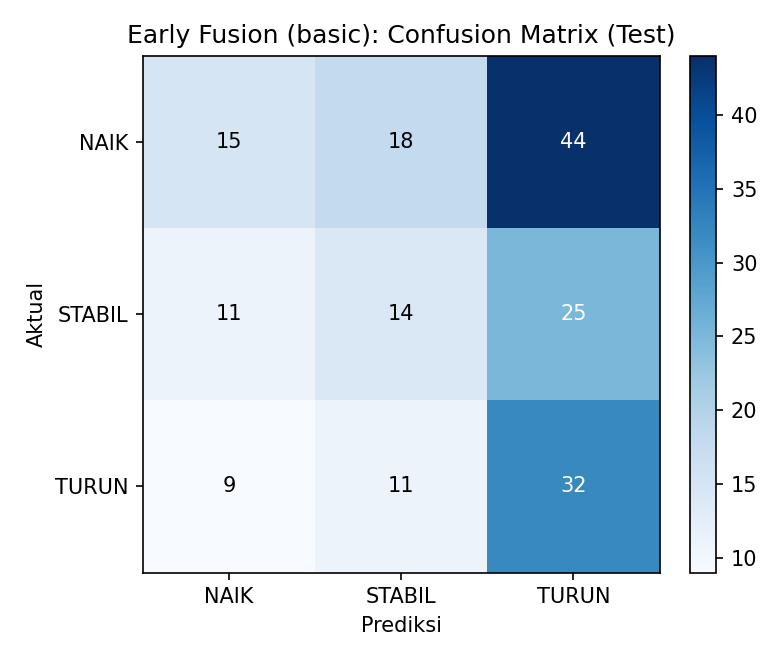

In [29]:
if RUN_HEAVY:
    from src.models.fusion_early import main as run_early
    from src.models.fusion_late import main as run_late
    run_early(["--text-group", "basic", "--output-prefix", "10_fusion_early_basic"])
    run_late(["--text-group", "basic", "--output-prefix", "11_fusion_late_basic"])

print("Early fusion (basic / Model B)")
display(show_results("10_fusion_early_basic_results.json"))
print("Late fusion (basic / Model B)")
display(show_results("11_fusion_late_basic_results.json"))
show_png("10_fusion_early_basic_confusion_matrix.png")

### 3.5 Studi Ablasi A/B/C + Model A+ (tuning) + Matriks Terpadu &nbsp;·&nbsp; `[Mikail]`

Tiga kontribusi Tugas 3 di satu tempat:
1. **Model A+** | Model A (TS-only) diperkaya indikator teknikal (moving averages + volatilitas multi-window) lalu **hyperparameter tuning** (RandomizedSearchCV + TimeSeriesSplit, tanpa lookahead). Modul: `src/models/xgb_ts_tuned.py`.
2. **Studi ablasi A/B/C/C+** | fitur transformer Model C berasal dari seksi 3.3 `[Rafi]`; notebook sumber `src/04b_ablation_study.ipynb`.
3. **Matriks terpadu Tugas 2 vs Tugas 3** | satu tabel apple-to-apple (`src/models/build_ablation_matrix.py`), deliverable 'Matriks Ablasi & Diskusi'.

Model A+ (TS diperkaya + tuned)


,split,accuracy,macro_f1,rmse,skill_vs_naive,directional_hit
0,val,0.3876,0.3820,55.7685,0.0020,0.5337
1,test,0.3464,0.3346,50.8071,0.0062,0.5754


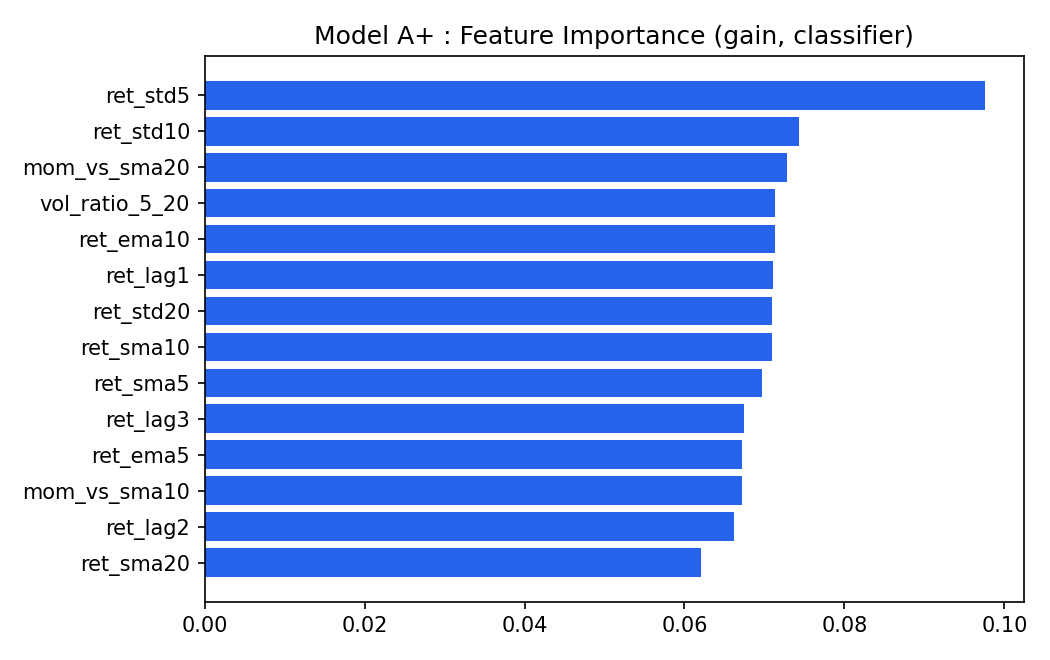


Studi Ablasi A/B/C/C+ (ringkasan test):


,model,split,task,accuracy,balanced_accuracy,macro_f1,kappa,rmse,mae,mape,skill_vs_naive,directional_hit
0,Naive Persistence,val,clf,0.3764,0.3695,0.3692,0.0577,NaN,NaN,NaN,NaN,NaN
1,Naive Majority-Class,val,clf,0.3876,0.3333,0.1862,0.0000,NaN,NaN,NaN,NaN,NaN
2,Naive Random Walk,val,reg,NaN,NaN,NaN,NaN,55.8789,40.7697,0.2473,0.0000,NaN
3,Naive Persistence,test,clf,0.3687,0.3562,0.3562,0.0326,NaN,NaN,NaN,NaN,NaN
4,Naive Majority-Class,test,clf,0.4302,0.3333,0.2005,0.0000,NaN,NaN,NaN,NaN,NaN
5,Naive Random Walk,test,reg,NaN,NaN,NaN,NaN,51.1231,38.5419,0.2214,0.0000,NaN
6,Model A: Hanya Time-Series,val,clf,0.3483,0.3478,0.3403,0.0185,NaN,NaN,NaN,NaN,NaN
7,Model A: Hanya Time-Series,test,clf,0.3408,0.3397,0.3304,0.0117,NaN,NaN,NaN,NaN,NaN
8,Model A: Hanya Time-Series,val,reg,NaN,NaN,NaN,NaN,55.3316,40.2267,0.2441,0.0098,0.5730
9,Model A: Hanya Time-Series,test,reg,NaN,NaN,NaN,NaN,51.2676,38.3238,0.2200,-0.0028,0.5196



=== MATRIKS ABLASI: Tugas 2 vs Tugas 3 (split TEST) ===
generasi                             model macro_f1  rmse skill_vs_naive directional_hit
Baseline    Naive Persistence of Direction   0.3562 51.12        +0.0000               -
 Tugas 2       Model A - TS-only (4 fitur)   0.3304 51.27        -0.0028          0.5196
 Tugas 2          Model B - TS + NLP dasar   0.2976 50.86        +0.0051          0.5866
 Tugas 2     Gabungan TS+NLP (early, awal)   0.3291 50.89        +0.0046          0.5866
 Tugas 3   Model A+ - TS diperkaya + tuned   0.3346 50.81        +0.0062          0.5754
 Tugas 3        Model C - TS + Transformer   0.3835 50.92        +0.0039          0.5810
 Tugas 3 Model C+ - TS + NLP + Transformer   0.3414 50.88        +0.0049          0.5866
 Tugas 3             Fusion Early (TS+NLP)   0.3291 50.89        +0.0046          0.5866
 Tugas 3              Fusion Late (TS+NLP)   0.3192 51.20        -0.0015          0.5140

[matrix] Tersimpan: ablation_matrix_tugas2_vs_tugas3

,model,generasi,macro_f1,rmse,skill_vs_naive,directional_hit,kalahkan_naive_clf,kalahkan_naive_reg
0,Naive Persistence of Direction,Baseline,0.3562,51.1231,0.0000,NaN,False,False
1,Model A - TS-only (4 fitur),Tugas 2,0.3304,51.2676,-0.0028,0.5196,False,False
2,Model B - TS + NLP dasar,Tugas 2,0.2976,50.8639,0.0051,0.5866,False,True
3,"Gabungan TS+NLP (early, awal)",Tugas 2,0.3291,50.8875,0.0046,0.5866,False,True
4,Model A+ - TS diperkaya + tuned,Tugas 3,0.3346,50.8071,0.0062,0.5754,False,True
5,Model C - TS + Transformer,Tugas 3,0.3835,50.9230,0.0039,0.5810,True,True
6,Model C+ - TS + NLP + Transformer,Tugas 3,0.3414,50.8751,0.0049,0.5866,False,True
7,Fusion Early (TS+NLP),Tugas 3,0.3291,50.8875,0.0046,0.5866,False,True
8,Fusion Late (TS+NLP),Tugas 3,0.3192,51.1995,-0.0015,0.5140,False,False


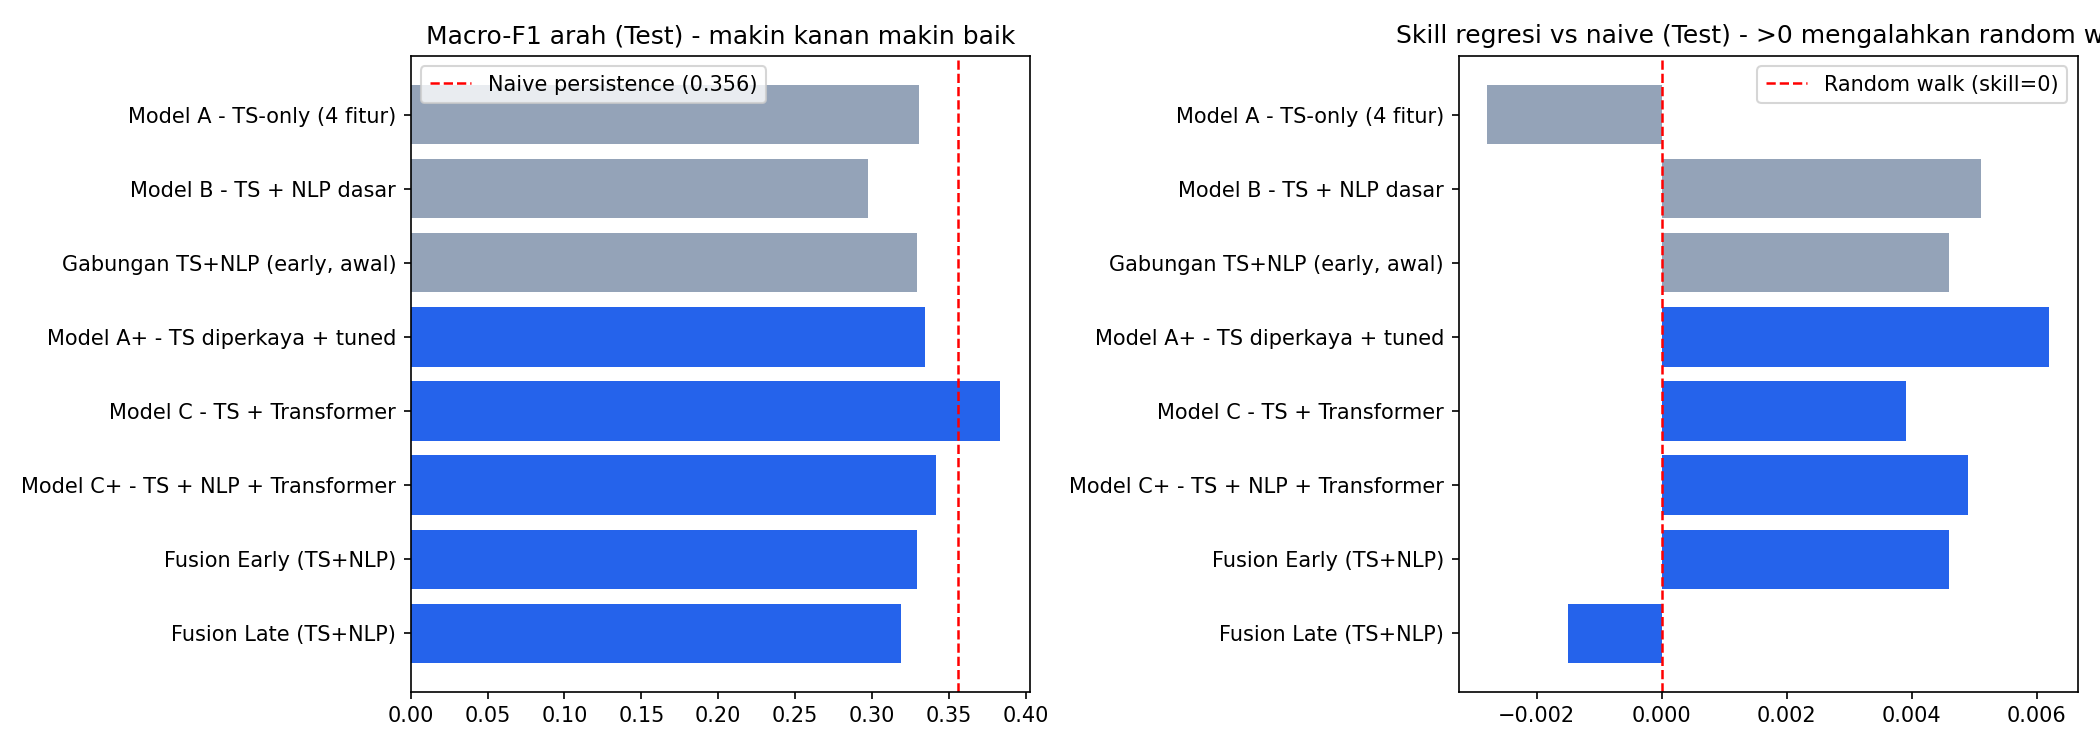

In [30]:
# 1) Model A+ : TS diperkaya + hyperparameter tuning (kontribusi Tugas 3)
if RUN_HEAVY:
    from src.models.xgb_ts_tuned import main as run_ts_tuned
    run_ts_tuned(["--n-iter", "50", "--cv-splits", "5",
                  "--output-prefix", "05b_ts_tuned"])

print("Model A+ (TS diperkaya + tuned)")
display(show_results("05b_ts_tuned_results.json"))
show_png("05b_ts_tuned_feature_importance.png", width=560)

# 2) Studi ablasi A/B/C/C+ (dihitung di src/04b_ablation_study.ipynb pada data bersih)
print("\nStudi Ablasi A/B/C/C+ (ringkasan test):")
display(pd.read_csv(PATHS['results'] / "04b_ablasi_comparison.csv"))

# 3) Matriks terpadu Tugas 2 vs Tugas 3 (agregasi semua hasil; ringan, selalu dijalankan)
from src.models.build_ablation_matrix import main as build_matrix
build_matrix([])
print("\nMatriks Ablasi Tugas 2 vs Tugas 3:")
display(pd.read_csv(PATHS['results'] / "ablation_matrix_tugas2_vs_tugas3.csv"))
show_png("ablation_matrix_tugas2_vs_tugas3.png", width=820)

### 3.6 Analisis Korelasi & Error &nbsp;·&nbsp; `[Mikail]`

Mengidentifikasi **tanggal** di mana fitur NLP membantu menghindari sinyal palsu
pasar vs tanggal di mana teks justru menambah noise | membandingkan prediksi TS-only
vs fusion, dengan uji McNemar. Modul: `src/models/error_correlation.py`.

Ringkasan analisis error (early fusion vs TS-only):
{
  "baseline": "XGBoost TS-only",
  "candidate": "Early Fusion (basic)",
  "split": "test",
  "n_dates": 179,
  "classification": {
    "nlp_helped": 18,
    "nlp_hurt": 23,
    "both_correct": 43,
    "both_wrong": 95,
    "net_help": -5,
    "mcnemar": {
      "p_value": 0.5327,
      "n_discordant": 41,
      "favored": "baseline (NLP merusak)"
    }
  },
  "regression": {
    "mae_base": 38.4611,
    "mae_cand": 38.1243,
    "dir_hit_base": 0.5028,
    "dir_hit_cand": 0.5866,
    "error_correlation": 0.9941,
    "dates_cand_closer": 90,
    "dates_base_closer": 89
  },
  "nlp_signal_vs_direction_corr": {
    "vader_title_mean": -0.0004,
    "vader_body_mean": -0.0153,
    "vader_neg_share": 0.0545,
    "lm_negative_mean": 0.0547,
    "lm_positive_mean": 0.061,
    "lm_net_mean": -0.0257
  }
}


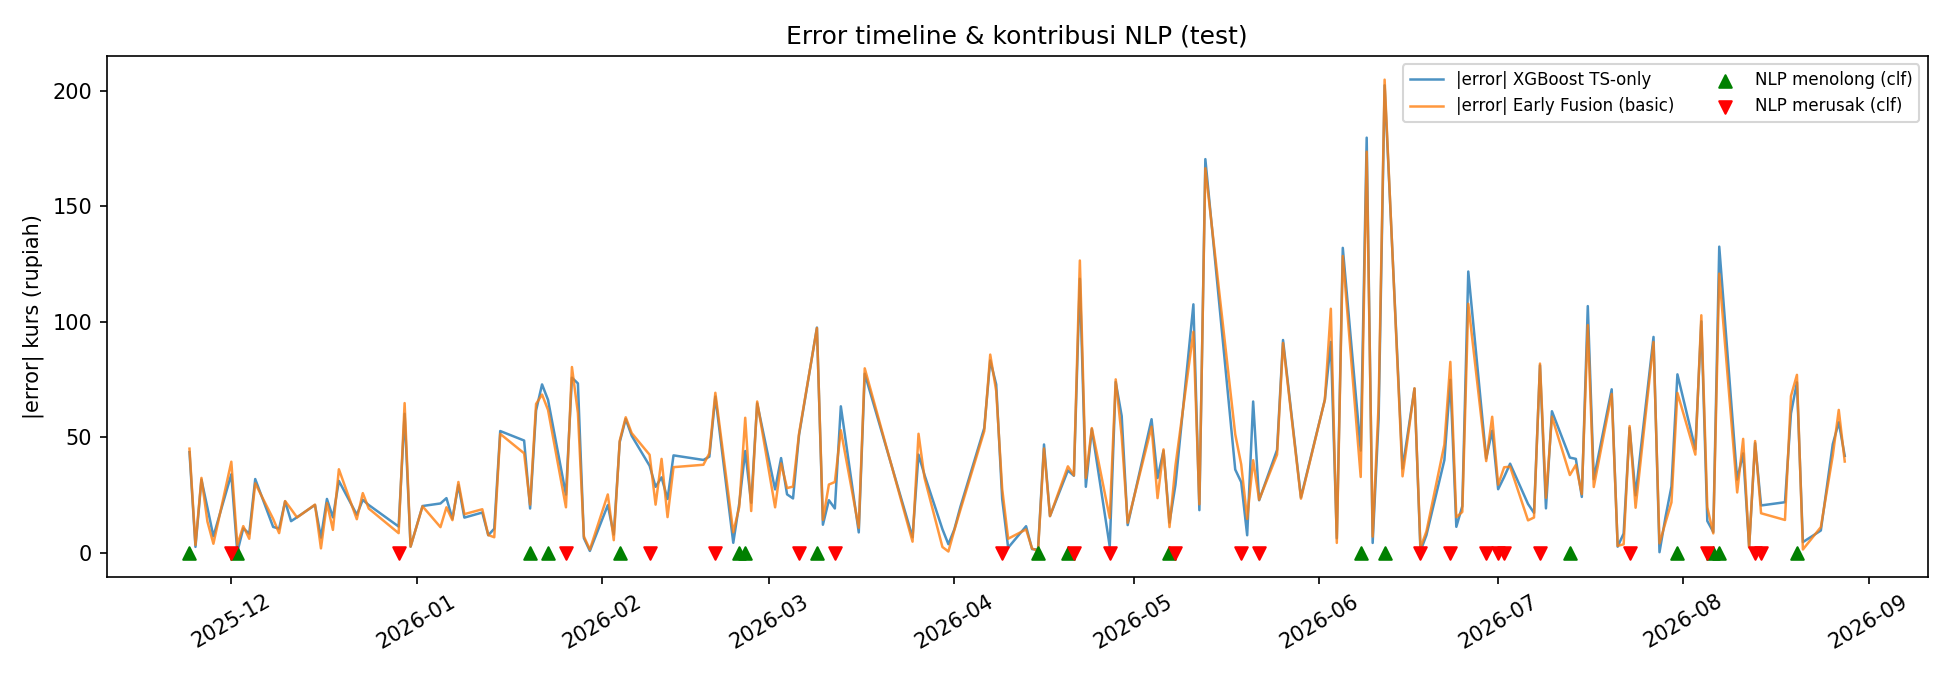

In [31]:
if RUN_HEAVY:
    from src.models.error_correlation import main as run_errcorr
    # Bandingkan prediksi TS-only (baseline) vs fusion ber-NLP (candidate)
    run_errcorr(["--baseline", "results/05_ts_only_predictions.csv",
                 "--candidate", "results/10_fusion_early_basic_predictions.csv",
                 "--output-prefix", "12_errcorr_early_basic"])

errcorr = load_json("12_errcorr_early_basic_summary.json")
print("Ringkasan analisis error (early fusion vs TS-only):")
print(json.dumps(errcorr, indent=2, ensure_ascii=False))
show_png("12_errcorr_early_basic_error_timeline.png", width=760)

---
## Lampiran Ringkasan Hasil Semua Eksperimen
---

In [32]:
# Rangkum metrik test dari semua *_results.json yang tersedia di results/.
import glob
rows = []
for p in sorted(glob.glob(str(PATHS["results"] / "*_results.json"))):
    try:
        d = json.load(open(p, encoding="utf-8"))
    except Exception:
        continue
    t = d.get("classification", {}).get("test", {})
    r = d.get("regression", {}).get("test", {})
    rows.append({
        "file": Path(p).name,
        "model": d.get("model", "?"),
        "test_macro_f1": t.get("macro_f1"),
        "test_rmse": r.get("rmse"),
        "skill_vs_naive": r.get("skill_vs_naive"),
    })
summary = pd.DataFrame(rows).sort_values("test_macro_f1", ascending=False, na_position="last")
summary.reset_index(drop=True)

,file,model,test_macro_f1,test_rmse,skill_vs_naive
0,09_glove_results.json,XGBoost GloVe NLP-only (tanpa fitur time-series),0.3357,51.0882,0.0007
1,05b_ts_tuned_results.json,XGBoost TS+ (enriched + tuned),0.3346,50.8071,0.0062
2,05_ts_only_results.json,XGBoost TS-only (tanpa NLP),0.3304,51.2676,-0.0028
3,04_gabungan_results.json,XGBoost Gabungan (TS+NLP),0.3291,50.8875,0.0046
4,10_fusion_early_basic_results.json,Early Fusion (basic),0.3291,50.8875,0.0046
5,11_fusion_late_basic_results.json,Late Fusion (basic),0.3192,51.1995,-0.0015
6,08_fasttext_results.json,XGBoost FastText NLP-only (tanpa fitur time-se...,0.3108,50.9107,0.0042
7,06_nlp_only_results.json,XGBoost NLP-only (tanpa kurs),0.2976,50.8639,0.0051
8,07_word2vec_results.json,XGBoost Word2Vec NLP-only (tanpa fitur time-se...,0.2964,50.7835,0.0066
9,07_word2vec_smoke_results.json,XGBoost Word2Vec NLP-only (tanpa fitur time-se...,0.2962,51.1409,-0.0003
